# Chapter 04: Stage 3A — Deep Learning Fundamentals (Neurons, Layers, Activations, Forward Pass, Loss & Backpropagation)

**Assalam-o-Alaikum!** Ab hum **Stage 3: Deep Learning** mein qadam rakh rahe hain!

### 1. Humein Deep Learning Ki Zaroorat Kyun Pari? (Why Traditional ML Is Insufficient)
- **Tabular Data (Excel/CSV):** Jab aap ke paas `5` ya `20` saaf columns (`area_marla`, `bedrooms`) hon, toh Scikit-learn (`LinearRegression`, `RandomForest`) behtareen kaam karta hai.
- **Unstructured & Complex Data (Images, Audio, Video, Raw Text, High-Frequency Sensors):** Ek choti si $224 	imes 224$ color tasveer mein **$150,528$ pixels** hote hain! Wahan haath se features banana namumkin hai. **Deep Learning (Multi-Layer Neural Networks)** raw data se khud hierarchical features seekhta hai!

### 2. Neural Network Ke 6 Bunyadi Hisse (Architecture Diagram)
```text
Input Features (x)      Hidden Layer (Neurons)         Output Layer (Prediction)
  [x1: Temp]    ----w11----> ( z = Wx + b ) ---> [ReLU] ---+
                             (            )                |---> ( Sigmoid ) ---> y_hat (Prob)
  [x2: Vib ]    ----w21----> ( Activation ) ---> [ReLU] ---+
```
1. **Neuron (Perceptron):** Har neuron inputs ko weights se multiply kar ke bias jorta hai: $z = \sum w_i x_i + b$.
2. **Activation Function (`ReLU`, `Sigmoid`, `Softmax`):** Agar Activation function na ho toh 100 layers wala network bhi sirf ek seedhi line (`LinearRegression`) ban kar reh jata hai!
   - **`ReLU(z) = max(0, z)`:** Hidden layers mein sab se zyada istemal hota hai (negative numbers ko `0` kar deta hai).
   - **`Sigmoid(z) = 1 / (1 + e^-z)`:** Output ko `0` aur `1` (Probability) ke darmiyan lata hai.
3. **Forward Propagation:** Input `x` ka layers se guzar kar prediction `y_hat` nikalna.
4. **Loss Function:** Prediction `y_hat` aur asal jawab `y` ke darmiyan ghalti naapna (`MSE` ya `BinaryCrossEntropy`).
5. **Backpropagation (Chain Rule):** Output se wapis peeche ki taraf chalte huye pata lagana ke kis weight (`W`) ne kitni ghalti ki ($rac{\partial 	ext{Loss}}{\partial W}$).
6. **Gradient Descent / Optimizer (`Adam`, `SGD`):** Weights ko ghalti ke ulat rukh par thora sa update karna: $W_{	ext{new}} = W_{	ext{old}} - \eta \cdot rac{\partial 	ext{Loss}}{\partial W}$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Step 1 — Visualize Activation Functions (`ReLU` vs `Sigmoid`)

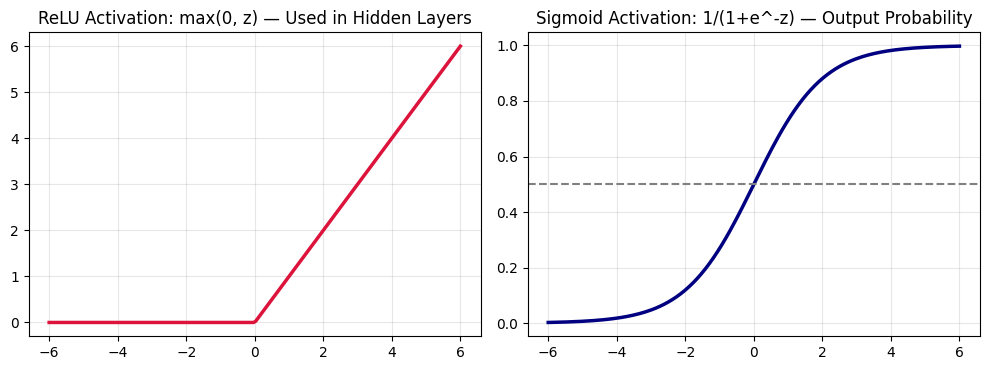

In [2]:
z = np.linspace(-6, 6, 200)
relu = np.maximum(0, z)
sigmoid = 1.0 / (1.0 + np.exp(-z))

plt.figure(figsize=(10, 3.8))
plt.subplot(1, 2, 1)
plt.plot(z, relu, color="crimson", lw=2.5)
plt.title("ReLU Activation: max(0, z) — Used in Hidden Layers")
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(z, sigmoid, color="navy", lw=2.5)
plt.axhline(0.5, color="gray", linestyle="--")
plt.title("Sigmoid Activation: 1/(1+e^-z) — Output Probability")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Step 2 — Build a Tiny 2-Layer Neural Network From Scratch (Forward Pass + Backprop + Gradient Descent)
PyTorch use karne se pehle hum 15 lines mein dekhenge ke **Forward Propagation**, **Loss Calculation**, aur **Backpropagation** andaruni taur par kaise kaam karte hain:

In [3]:
database = pd.read_excel("datasets/sensor_failure.xlsx")
x = database[["temperature_c", "vibration_mm", "pressure_bar", "motor_rpm"]].values
y = database["machine_failure"].values.reshape(-1, 1)

# Standardize inputs
x_sc = (x - x.mean(axis=0)) / x.std(axis=0)

# Initialize tiny Neural Network weights (4 inputs -> 4 hidden ReLU neurons -> 1 Sigmoid output)
rng = np.random.RandomState(42)
W1 = rng.normal(0, 0.3, (4, 4))
b1 = np.zeros((1, 4))
W2 = rng.normal(0, 0.3, (4, 1))
b2 = np.zeros((1, 1))

lr = 0.15
loss_history = []

for epoch in range(1, 101):
    # 1. Forward Propagation
    z1 = x_sc @ W1 + b1
    a1 = np.maximum(0, z1)                      # ReLU Hidden Layer
    z2 = a1 @ W2 + b2
    y_hat = 1.0 / (1.0 + np.exp(-z2))           # Sigmoid Output Layer

    # 2. Binary Cross-Entropy Loss
    loss = -np.mean(y * np.log(y_hat + 1e-8) + (1 - y) * np.log(1 - y_hat + 1e-8))
    loss_history.append(loss)

    # 3. Backpropagation (Chain Rule Gradients)
    dz2 = (y_hat - y) / len(y)
    dW2 = a1.T @ dz2
    db2 = np.sum(dz2, axis=0, keepdims=True)

    da1 = dz2 @ W2.T
    dz1 = da1 * (z1 > 0)                        # Derivative of ReLU
    dW1 = x_sc.T @ dz1
    db1 = np.sum(dz1, axis=0, keepdims=True)

    # 4. Gradient Descent Weight Update
    W1 -= lr * dW1
    b1 -= lr * db1
    W2 -= lr * dW2
    b2 -= lr * db2

preds = (y_hat >= 0.5).astype(int)
acc: float = float(np.mean(preds == y) * 100)
print(f"Initial Loss (Epoch 1): {loss_history[0]:.4f} -> Final Loss (Epoch 100): {loss_history[-1]:.4f}")
print(f"Tiny Neural Network Accuracy: {acc:.2f}%")

Initial Loss (Epoch 1): 0.7521 -> Final Loss (Epoch 100): 0.2095
Tiny Neural Network Accuracy: 94.00%


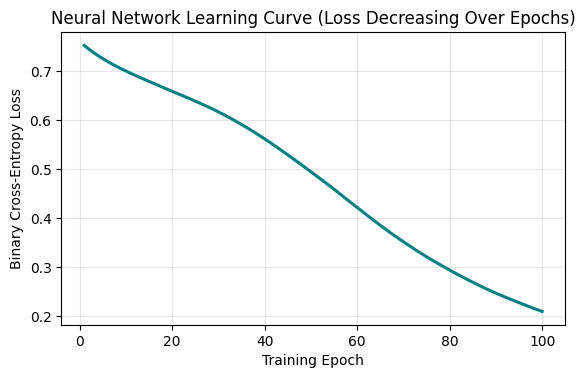

In [4]:
plt.figure(figsize=(6.5, 3.8))
plt.plot(range(1, 101), loss_history, color="teal", lw=2.2)
plt.xlabel("Training Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Neural Network Learning Curve (Loss Decreasing Over Epochs)")
plt.grid(True, alpha=0.3)
plt.show()

### Step 3 — Inspect Dataset (`database.head(5)`, `database.shape`, `database.isnull().sum()`)

In [5]:
database.head(5)

,temperature_c,vibration_mm,pressure_bar,motor_rpm,machine_failure
0,73.3,1.62,5.74,2761,0
1,69.7,8.79,4.46,1246,1
2,65.9,8.33,5.31,1977,1
3,100.8,5.17,4.62,2239,1
4,94.8,5.82,3.77,1910,1


In [6]:
database.shape, database.isnull().sum().to_dict()

((100, 5), {'temperature_c': 0, 'vibration_mm': 0, 'pressure_bar': 0, 'motor_rpm': 0, 'machine_failure': 0})

### Step 4 — Line-by-Line Explanation of Forward Pass & Backpropagation
- `z1 = x_sc @ W1 + b1`: Input features ko Layer 1 ke weights se multiply kar ke bias jora.
- `a1 = np.maximum(0, z1)`: **ReLU Activation** lagaya jis ne negative values ko `0` kar diya.
- `y_hat = 1.0 / (1.0 + np.exp(-z2))`: **Sigmoid Activation** ne output ko `0.0` se `1.0` probability mein badal diya.
- `W1 -= lr * dW1`: **Gradient Descent** ne loss kam karne ke liye weights ko update kiya.

### Step 5 — Common Deep Learning Error: Learning Rate (`lr`) Too High vs Too Low
Agar `lr` bohot bada (`10.0`) ho toh Loss kam hone ke bajaye explode kar jata hai; aur agar `lr` bohot chota (`0.00001`) ho toh network bohot sust seekhta hai:

In [7]:
for test_lr in [0.001, 0.05, 0.15]:
    w_temp = np.zeros((4, 1))
    for _ in range(50):
        p = 1.0 / (1.0 + np.exp(-(x_sc @ w_temp)))
        w_temp -= test_lr * (x_sc.T @ (p - y)) / len(y)
    loss_val = -np.mean(y * np.log(p + 1e-8) + (1 - y) * np.log(1 - p + 1e-8))
    print(f"Learning Rate lr={test_lr:5.3f} -> Loss after 50 epochs: {loss_val:.4f}")

Learning Rate lr=0.001 -> Loss after 50 epochs: 0.6856
Learning Rate lr=0.050 -> Loss after 50 epochs: 0.4735
Learning Rate lr=0.150 -> Loss after 50 epochs: 0.3508


### Step 6 — Practical Student Exercise: Predict Sensor Failure Using Learned Neural Weights
Ek nayi factory machine (`temperature_c=95.0, vibration_mm=8.2, pressure_bar=6.0, motor_rpm=3100`) par forward pass chala kar failure probability nikalein:

In [8]:
# Practical Exercise — Working Solution
new_machine = np.array([[95.0, 8.2, 6.0, 3100.0]])
new_machine_sc = (new_machine - x.mean(axis=0)) / x.std(axis=0)
h1 = np.maximum(0, new_machine_sc @ W1 + b1)
prob_fail = float((1.0 / (1.0 + np.exp(-(h1 @ W2 + b2))))[0, 0])
print(f"New Machine Failure Probability: {prob_fail*100:.1f}% -> Class: {int(prob_fail >= 0.5)}")

New Machine Failure Probability: 86.9% -> Class: 1


### Chapter 04 Revision Quiz
1. **Hidden layer mein `ReLU` kyun lagate hain?** Non-linear patterns seekhne aur vanishing gradient se bachne ke liye.
2. **Forward Pass aur Backpropagation mein kya farq hai?** Forward pass input se prediction nikalta hai; Backpropagation loss se wapis chal kar har weight ka gradient ($\partial L / \partial W$) nikalta hai.